# Cvičenie 8

Šum a jeho odstránenie.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import skimage as sk

## Úloha 1

Porovnanie druhov šumu - pomocou funkcii skimage vygenerujte zašumné obrázky.

C:\Users\bobko\OneDrive\PC\Projects\FEI\Ing\3. semester Ing\CSO\python\.venv\Lib\site-packages\skimage\metrics\simple_metrics.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


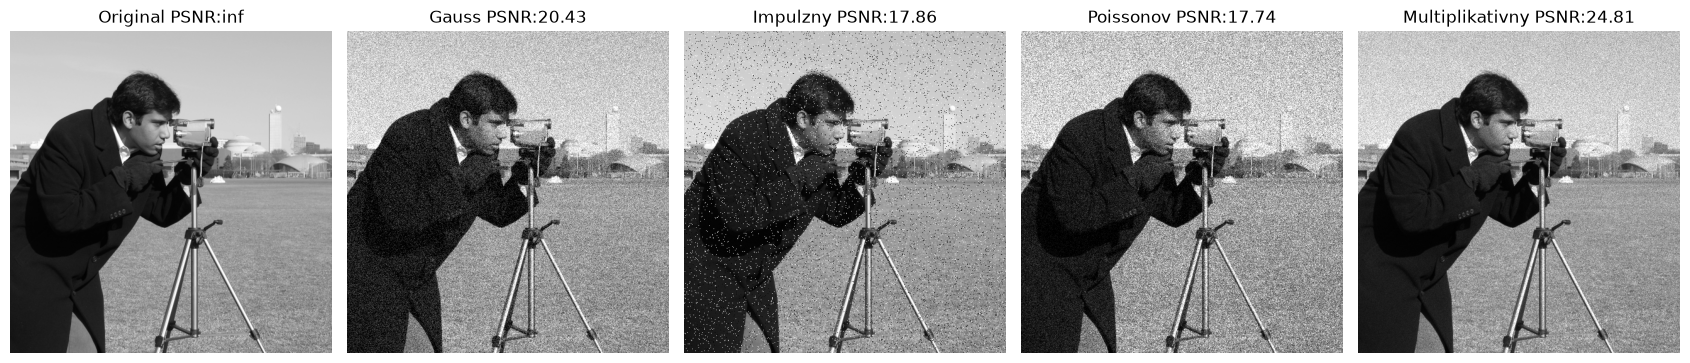

In [3]:
image = sk.util.img_as_float(sk.data.camera())
rng = np.random.default_rng(seed=6)
sigma = 0.1

noisy_gauss = sk.util.random_noise(image, mode="gaussian", var=sigma**2, rng=rng) # s tymto obrazkom budeme pracovat pri odsumovani
impulse = sk.util.random_noise(image, mode="s&p", amount=0.05, rng=rng)  # 5 % pixelov je čierna/biela
peak = 30      # menší peak = silnejší šum
poisson = rng.poisson(image * peak) / peak  # >= 0, ale môže presiahnuť 1

speckle = sk.util.random_noise(image, mode="speckle", var=sigma**2, rng=rng)  # multiplikatívny: obraz + obraz * n

fig, ax = plt.subplots(1, 5, figsize=(17, 5))
for a, obr, nazov in zip(ax, [image, noisy_gauss, impulse, poisson, speckle],
                         ["Original", "Gauss", "Impulzny", "Poissonov", "Multiplikativny"]):
    a.imshow(np.clip(obr, 0, 1), cmap="gray", vmin=0, vmax=1)
    a.set_title(f"{nazov} PSNR:{sk.metrics.peak_signal_noise_ratio(image, obr):.2f}" )
    a.axis("off")
plt.tight_layout()
plt.show()

## Úloha 2

Odhad úrovne šumu - doplňte výrez homogénnej oblasti obrázka a porovnajte s "estimate_sigma" zo skimage.

jednoduchy odhad: 0.097 
sk funkcia: 0.096 
skutočná hodnota: 0.1


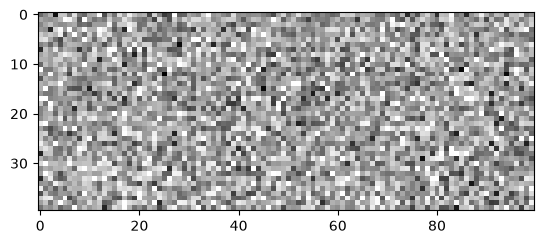

In [4]:
plocha = noisy_gauss[40:80, 0:100]   # homogénna obloha vľavo hore (pôvodný obraz tu má std ~ 0.005)
plt.imshow(plocha, cmap="gray")
sk_odhad = sk.restoration.estimate_sigma(noisy_gauss)
print(f"jednoduchy odhad: {plocha.std():.3f} \nsk funkcia: {sk_odhad:.3f} \nskutočná hodnota: {sigma}")

## Úloha 3

Fúzia obrázkov - doplňte funkciu fuzia (napríklad podľa prednášky).

In [ ]:
def fuzia(pocet=5, sigma=0.1):
    rng = np.random.default_rng(0)   # pevný seed, aby sa pri posune slidera nemenil prvý obraz
    # pocet nezávislých zašumených snímok tej istej scény, os -1 = index snímky (H, W, pocet)
    # (bez orezania na [0, 1], aby bol šum nulovej strednej hodnoty a platilo sigma/sqrt(N))
    skupina = image[..., None] + sigma * rng.standard_normal(image.shape + (pocet,))
    priemer = skupina.mean(axis=-1)
    psnr_1 = sk.metrics.peak_signal_noise_ratio(image, skupina[..., 0], data_range=1)
    psnr_N = sk.metrics.peak_signal_noise_ratio(image, priemer, data_range=1)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(skupina[..., 0], cmap="gray", vmin=0, vmax=1)
    ax[0].set_title(f"1 zašumený obraz, PSNR = {psnr_1:.1f} dB")
    ax[1].imshow(priemer, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title(f"priemer z {pocet}: PSNR = {psnr_N:.1f} dB )")
    for a in ax:
        a.axis("off")
    plt.show()

widgets.interact(
    fuzia,
    pocet=widgets.IntSlider(value=5, min=1, max=100, description="počet",
                            continuous_update=False),
    sigma=widgets.FloatSlider(value=0.1, min=0.01, max=0.5, step=0.01, description="σ",
                              continuous_update=False),
);

interactive(children=(IntSlider(value=5, continuous_update=False, description='počet', min=1), FloatSlider(val…

## Úloha 4

Odšumovanie - Denoising
Vyberte 4 metódy - 2 klasické (z prednášky) a 2 neurónové (z dokumentácie deep inverse).
Pomocou šablóny na konci spravte ich porovnanie.

**Vybraté metódy by ste mali vedieť stručne opísať.**

In [6]:
import torch
import deepinv as dinv

device = ("cuda" if torch.cuda.is_available()
              else "mps" if torch.backends.mps.is_available() else "cpu")

def na_tenzor(obraz):            # numpy (H, W) → tenzor (1, 1, H, W)
    return torch.from_numpy(obraz.astype(np.float32))[None, None].to(device)

def na_numpy(t):                 # tenzor (1, 1, H, W) → numpy (H, W)
    return t.detach().cpu().numpy()[0, 0]

In [7]:
# 1. klasická metóda: Non-Local Means (skimage)
# NLM potrebuje poznať úroveň šumu, tak ju odhadneme (Úloha 2)
sigma_odhad = sk.restoration.estimate_sigma(noisy_gauss)
denoised_1 = sk.restoration.denoise_nl_means(
    noisy_gauss, patch_size=7, patch_distance=10,
    h=0.6 * sigma_odhad, sigma=sigma_odhad, fast_mode=True)

In [8]:
# 2. klasická metóda: minimalizácia totálnej variácie (Chambolle, skimage)
# weight zodpovedá lambda: väčšie = silnejšie vyhladenie ("kreslený" vzhľad)
denoised_2 = sk.restoration.denoise_tv_chambolle(noisy_gauss, weight=0.08)

In [9]:
# 3. neurónová metóda: DRUNet (deepinv), predtrénované váhy pre šedotónové obrazy
# (pri prvom spustení sa stiahnu z HuggingFace, ~125 MB)
drunet = dinv.models.DRUNet(in_channels=1, out_channels=1, pretrained="download", device=device).eval()
with torch.no_grad():
    denoised_3 = np.clip(na_numpy(drunet(na_tenzor(noisy_gauss), sigma)), 0, 1)  # sigma = úroveň šumu

In [10]:
# 4. neurónová metóda: FFDNet (deepinv), predtrénované šedotónové váhy
ffdnet = dinv.models.FFDNet(pretrained="download", device=device).eval()
with torch.no_grad():
    denoised_4 = np.clip(na_numpy(ffdnet(na_tenzor(noisy_gauss), sigma)), 0, 1)

In [15]:
vysledky = {
    "Non-Local Means":  denoised_1,
    "Chambolle":  denoised_2,
    "DRUNet": denoised_3,
    "FFDNet": denoised_4,
}

psnr = [sk.metrics.peak_signal_noise_ratio(image, v, data_range=1) for v in vysledky.values()]

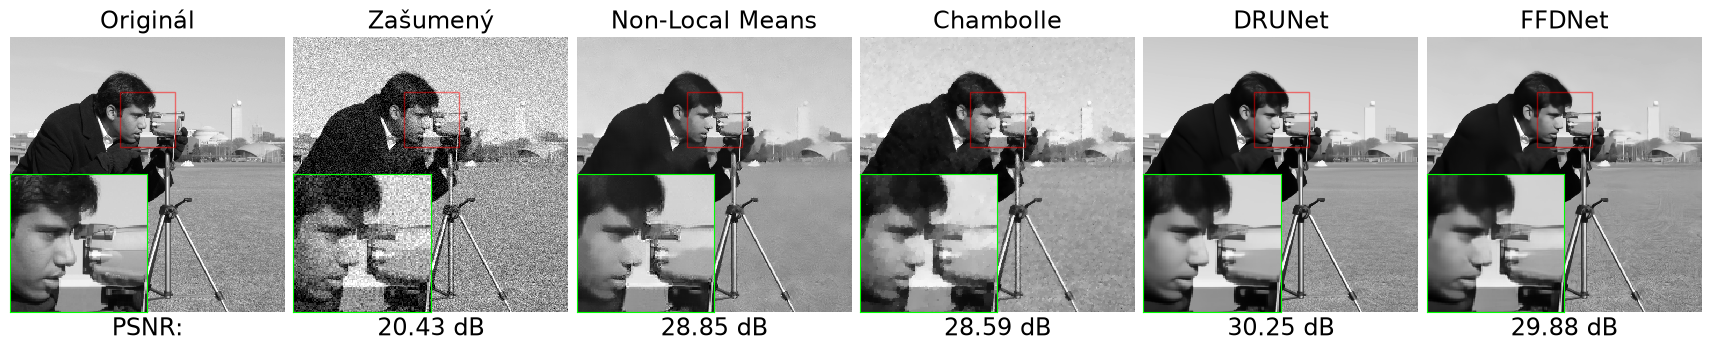

In [16]:
dinv.utils.plot(
    plot_inset=True,
    img_list=[na_tenzor(image), na_tenzor(noisy_gauss)] + [na_tenzor(v) for v in vysledky.values()],
    titles=["Originál", "Zašumený"] + list(vysledky),
    subtitles=["PSNR:", f"{sk.metrics.peak_signal_noise_ratio(image, noisy_gauss, data_range=1):.2f} dB"]
              + [f"{p:.2f} dB" for p in psnr],
    extract_size=0.2, extract_loc=(0.4, 0.2), inset_size=0.5, figsize=(17, 5),
)